# 6. El test detrás de cada decisión

Cada decisión del modelo tiene un código `Dnn` que aparece como comentario en el código. La lista y los tests están en `pruebas.py`, y `python correr.py decisiones` los corre y genera `docs/DECISIONES.md`.

Para comparar dos modelos se usa el t pareado corregido de Nadeau y Bengio, porque los folds comparten datos y un t común daría demasiados falsos positivos. Después se corrige por la cantidad de tests con Holm.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")  # Los módulos están en la raíz del proyecto
warnings.filterwarnings("ignore")
%matplotlib inline

from IPython.display import Markdown
import matplotlib.pyplot as plt
import pandas as pd

import datos
import modelo
import pruebas

corridas = modelo.leer()

def por_fold(nota, tipo):
    return [r for r in corridas if r.get("nota") == nota and r["tipo"] == tipo][-1]["accuracy_por_fold"]

def aporte(nombre, sufijo, tipo):
    return 100 * pruebas.t_corregido(por_fold(f"decisiones: modelo completo{sufijo}", tipo),
                                     por_fold(f"decisiones: sin {nombre}{sufijo}", tipo))[0]

## Cuánto aporta cada pieza

Cuánto se pierde al sacar cada pieza, medido dos veces, con los folds de siempre y con folds nuevos. Si una mejora fuera suerte de los folds, no se repetiría. Las piezas grandes se repiten; las de efecto casi nulo oscilan alrededor de cero.

,folds de siempre,folds nuevos
pieza,,
Features derivadas del item,0.642,0.589
Todo el target encoding junto,0.588,0.559
Desfasaje en la duración,0.374,0.349
Los tres perfiles juntos,0.264,0.242
Tipo de publicación y estado,0.249,0.234
Palabras clave en título y garantía,0.204,0.167
Todas las piezas de efecto casi nulo juntas,0.149,0.204
Ficha técnica,0.126,0.087
Vecinos por título,0.125,0.085


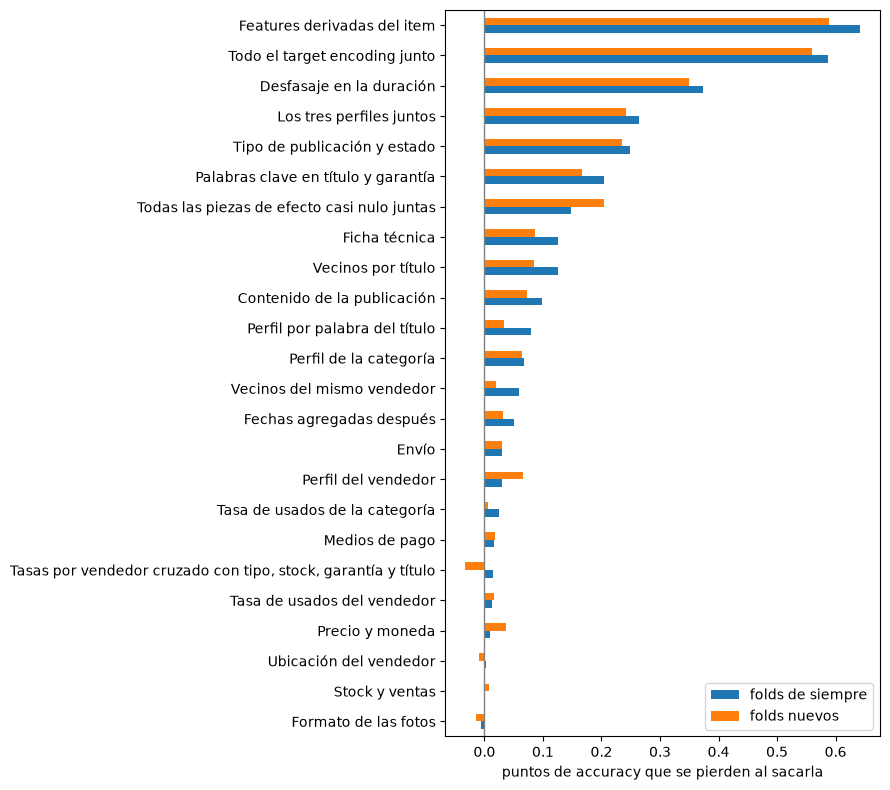

In [2]:
aportes = pd.DataFrame([
    {"pieza": nombre, "folds de siempre": aporte(nombre, "", "validacion"),
     "folds nuevos": aporte(nombre, " (semillas [2, 3])", "control")}
    for _, nombre, _ in pruebas.ABLACIONES
]).set_index("pieza").sort_values("folds de siempre")
aportes.plot.barh(figsize=(9, 8), xlabel="puntos de accuracy que se pierden al sacarla", ylabel="")
plt.axvline(0, color="grey", lw=1)
plt.tight_layout()
aportes.round(3).sort_values("folds de siempre", ascending=False)

## Se intentó sacar más

Se probó sacar los grupos de menor aporte de a uno, mientras la pérdida acumulada fuera menor a 0.02 puntos. Quedaban cuatro, que eran el formato de las fotos, la ubicación, la tasa del vendedor y las fechas agregadas. El límite y la regla se fijaron antes de correr.

La confirmación se hizo con folds que no se habían mirado nunca, y ahí la pérdida superó el límite. Por eso esas variables se quedan (D53).

In [3]:
completo = por_fold("simplificar: confirmacion completo", "control")
reducido = por_fold("simplificar: confirmacion reducido", "control")
print(f"Pérdida en folds nuevos de {100 * (sum(completo) - sum(reducido)) / len(completo):.3f} puntos, con un límite de 0.02")

Pérdida en folds nuevos de 0.029 puntos, con un límite de 0.02


## La tabla completa

Un p alto no prueba que una pieza no aporte, porque con 10 folds y tantos tests solo se detectan las diferencias grandes. "Sin respaldo" significa que no se demostró la mejora, no que haya que sacarla.

In [4]:
Markdown((datos.DOCS / "DECISIONES.md").read_text(encoding="utf8"))

# Decisiones y sus tests

Generado por `python correr.py decisiones`.

Cada decisión se prueba dos veces. Primero con los folds de siempre (semillas 0 y 1) y después con folds nuevos (semillas 2 y 3), para confirmar que una mejora no fue suerte de cómo cayeron los folds. Las decisiones sobre los datos y las comparaciones registradas antes tienen una sola medición.

Las comparaciones de modelos usan el t pareado corregido de Nadeau y Bengio sobre los 10 folds, con corrección de Holm por la cantidad de tests (su p ya está ajustado). La diferencia es con la pieza menos sin la pieza, en puntos de accuracy, casi siempre medida con LightGBM.

Los veredictos posibles son **respaldada** (al conservar, la pieza suma de forma significativa; al descartar, no se demostró que sume), **sin respaldo** (se conserva algo sin una mejora demostrada), **contradicha** (el test indica lo contrario) y **sin test**.

Un p alto no prueba que una pieza no aporte, porque con 10 folds y tantos tests solo se detectan las diferencias grandes. Además, sacar una pieza sola subestima su aporte si otra lleva información parecida, por eso algunas se prueban juntas.

Con los folds de siempre hay 43 respaldada, 20 sin respaldo. Con folds nuevos hay 20 sin respaldo, 7 respaldada.

| Código   | Decisión                                                                                                 | Folds de siempre                                    | p       | Veredicto    | Folds nuevos                       | p con folds nuevos   | Veredicto con folds nuevos   |
|:---------|:---------------------------------------------------------------------------------------------------------|:----------------------------------------------------|:--------|:-------------|:-----------------------------------|:---------------------|:-----------------------------|
| D01      | Validar con folds al azar, porque train y test son intercambiables                                       | Mann-Whitney, AUC 0.497                             | 0.122   | respaldada   |                                    |                      |                              |
| D02      | Descartar columnas constantes                                                                            | sin test, porque una constante no puede asociarse   |         | respaldada   |                                    |                      |                              |
| D03      | Usar la ausencia de `official_store_id` como señal                                                       | chi cuadrado, usados 46.7% si falta y 3.0% si está  | < 0.001 | respaldada   |                                    |                      |                              |
| D03      | Usar la ausencia de `parent_item_id` como señal                                                          | chi cuadrado, usados 45.2% si falta y 46.6% si está | 0.002   | respaldada   |                                    |                      |                              |
| D03      | Usar la ausencia de `video_id` como señal                                                                | chi cuadrado, usados 47.0% si falta y 23.0% si está | < 0.001 | respaldada   |                                    |                      |                              |
| D03      | Usar la ausencia de `warranty` como señal                                                                | chi cuadrado, usados 51.6% si falta y 38.0% si está | < 0.001 | respaldada   |                                    |                      |                              |
| D10      | Conservar tipo de publicación y estado                                                                   | t corregido, +0.249 ± 0.049 puntos                  | 0.030   | respaldada   | t corregido, +0.234 ± 0.042 puntos | 0.018                | respaldada                   |
| D11      | Conservar precio y moneda                                                                                | t corregido, +0.009 ± 0.031 puntos                  | 1.000   | sin respaldo | t corregido, +0.036 ± 0.034 puntos | 1.000                | sin respaldo                 |
| D12      | Conservar stock y ventas                                                                                 | t corregido, +0.000 ± 0.034 puntos                  | 1.000   | sin respaldo | t corregido, +0.008 ± 0.045 puntos | 1.000                | sin respaldo                 |
| D14      | Conservar ubicación del vendedor                                                                         | t corregido, +0.003 ± 0.032 puntos                  | 1.000   | sin respaldo | t corregido, -0.009 ± 0.030 puntos | 1.000                | sin respaldo                 |
| D15      | Conservar envío                                                                                          | t corregido, +0.030 ± 0.026 puntos                  | 1.000   | sin respaldo | t corregido, +0.031 ± 0.029 puntos | 1.000                | sin respaldo                 |
| D16      | Conservar medios de pago                                                                                 | t corregido, +0.017 ± 0.033 puntos                  | 1.000   | sin respaldo | t corregido, +0.019 ± 0.041 puntos | 1.000                | sin respaldo                 |
| D17      | Conservar contenido de la publicación                                                                    | t corregido, +0.099 ± 0.036 puntos                  | 0.842   | sin respaldo | t corregido, +0.074 ± 0.046 puntos | 1.000                | sin respaldo                 |
| D18      | Conservar ficha técnica                                                                                  | t corregido, +0.126 ± 0.049 puntos                  | 1.000   | sin respaldo | t corregido, +0.087 ± 0.039 puntos | 1.000                | sin respaldo                 |
| D19      | Conservar features derivadas del item                                                                    | t corregido, +0.642 ± 0.040 puntos                  | < 0.001 | respaldada   | t corregido, +0.589 ± 0.065 puntos | < 0.001              | respaldada                   |
| D20      | Conservar palabras clave en título y garantía                                                            | t corregido, +0.204 ± 0.040 puntos                  | 0.031   | respaldada   | t corregido, +0.167 ± 0.042 puntos | 0.138                | sin respaldo                 |
| D21      | Conservar perfil del vendedor                                                                            | t corregido, +0.029 ± 0.045 puntos                  | 1.000   | sin respaldo | t corregido, +0.066 ± 0.040 puntos | 1.000                | sin respaldo                 |
| D22      | Conservar perfil de la categoría                                                                         | t corregido, +0.067 ± 0.043 puntos                  | 1.000   | sin respaldo | t corregido, +0.065 ± 0.035 puntos | 1.000                | sin respaldo                 |
| D23      | Conservar perfil por palabra del título                                                                  | t corregido, +0.080 ± 0.041 puntos                  | 1.000   | sin respaldo | t corregido, +0.034 ± 0.039 puntos | 1.000                | sin respaldo                 |
| D24      | Conservar formato de las fotos                                                                           | t corregido, -0.006 ± 0.026 puntos                  | 1.000   | sin respaldo | t corregido, -0.014 ± 0.043 puntos | 1.000                | sin respaldo                 |
| D25      | Conservar desfasaje en la duración                                                                       | t corregido, +0.374 ± 0.058 puntos                  | 0.006   | respaldada   | t corregido, +0.349 ± 0.067 puntos | 0.026                | respaldada                   |
| D26      | Conservar fechas agregadas después                                                                       | t corregido, +0.050 ± 0.034 puntos                  | 1.000   | sin respaldo | t corregido, +0.032 ± 0.041 puntos | 1.000                | sin respaldo                 |
| D27      | Conservar los tres perfiles juntos                                                                       | t corregido, +0.264 ± 0.062 puntos                  | 0.093   | sin respaldo | t corregido, +0.242 ± 0.064 puntos | 0.178                | sin respaldo                 |
| D30      | Conservar tasa de usados del vendedor                                                                    | t corregido, +0.014 ± 0.038 puntos                  | 1.000   | sin respaldo | t corregido, +0.017 ± 0.031 puntos | 1.000                | sin respaldo                 |
| D31      | Conservar tasa de usados de la categoría                                                                 | t corregido, +0.024 ± 0.037 puntos                  | 1.000   | sin respaldo | t corregido, +0.006 ± 0.037 puntos | 1.000                | sin respaldo                 |
| D32      | Conservar vecinos por título                                                                             | t corregido, +0.125 ± 0.058 puntos                  | 1.000   | sin respaldo | t corregido, +0.085 ± 0.068 puntos | 1.000                | sin respaldo                 |
| D33      | Conservar tasas por vendedor cruzado con tipo, stock, garantía y título                                  | t corregido, +0.014 ± 0.030 puntos                  | 1.000   | sin respaldo | t corregido, -0.033 ± 0.060 puntos | 1.000                | sin respaldo                 |
| D34      | Conservar vecinos del mismo vendedor                                                                     | t corregido, +0.059 ± 0.035 puntos                  | 1.000   | sin respaldo | t corregido, +0.019 ± 0.042 puntos | 1.000                | sin respaldo                 |
| D35      | Conservar todo el target encoding junto                                                                  | t corregido, +0.588 ± 0.053 puntos                  | < 0.001 | respaldada   | t corregido, +0.559 ± 0.076 puntos | 0.002                | respaldada                   |
| D36      | Conservar todas las piezas de efecto casi nulo juntas                                                    | t corregido, +0.149 ± 0.034 puntos                  | 0.075   | sin respaldo | t corregido, +0.204 ± 0.059 puntos | 0.280                | sin respaldo                 |
| D40      | Usar 30 vecinos por título y no 10                                                                       | t corregido, -0.030 ± 0.057 puntos                  | 1.000   | respaldada   | t corregido, +0.016 ± 0.028 puntos | 1.000                | respaldada                   |
| D41      | Suavizar las tasas con 2 y no con 10                                                                     | t corregido, +0.021 ± 0.032 puntos                  | 1.000   | respaldada   | t corregido, -0.005 ± 0.028 puntos | 1.000                | respaldada                   |
| D42      | Suavizar las tasas con 2 y no con 0.5                                                                    | t corregido, -0.001 ± 0.043 puntos                  | 1.000   | respaldada   | t corregido, -0.023 ± 0.034 puntos | 1.000                | respaldada                   |
| D50      | Usar solo LightGBM y no promediar cuatro modelos                                                         | t corregido, +0.038 ± 0.024 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D51      | No adoptar los hiperparámetros de la última búsqueda                                                     | t corregido, +0.001 ± 0.025 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D52      | Cortar en 0.5 y no en 0.48, el mejor valor visto                                                         | McNemar, diferencia +0.019 puntos                   | 0.182   | respaldada   |                                    |                      |                              |
| D53      | Conservar fotos, ubicación, tasa del vendedor y fechas, porque sacarlas juntas pierde más de 0.02 puntos | t corregido, +0.029 ± 0.035 puntos                  | 1.000   | sin respaldo |                                    |                      |                              |
| D60      | Sacar el modelo de texto (en LightGBM; además fue pedido tuyo)                                           | t corregido, +0.041 ± 0.048 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D61      | Sacar las pseudo-etiquetas                                                                               | t corregido, +0.044 ± 0.034 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D62      | Sacar Random Forest frente a LightGBM                                                                    | t corregido, -0.780 ± 0.087 puntos                  | < 0.001 | respaldada   |                                    |                      |                              |
| D63      | Sacar Extra Trees frente a LightGBM                                                                      | t corregido, -0.730 ± 0.090 puntos                  | < 0.001 | respaldada   |                                    |                      |                              |
| D64      | Sacar regresión logística frente a LightGBM                                                              | t corregido, -1.060 ± 0.127 puntos                  | < 0.001 | respaldada   |                                    |                      |                              |
| D65      | No usar red neuronal frente a LightGBM                                                                   | t corregido, -0.769 ± 0.070 puntos                  | < 0.001 | respaldada   |                                    |                      |                              |
| D66      | No usar kNN frente a LightGBM                                                                            | t corregido, -4.357 ± 0.128 puntos                  | < 0.001 | respaldada   |                                    |                      |                              |
| D67      | No usar clustering frente a LightGBM                                                                     | t corregido, -5.875 ± 0.092 puntos                  | < 0.001 | respaldada   |                                    |                      |                              |
| D68      | No sumar kNN ni clustering como variables                                                                | t corregido, +0.016 ± 0.039 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D69      | Sacar las palabras clave nuevas                                                                          | t corregido, +0.000 ± 0.036 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D70      | Sacar el subdominio de la URL                                                                            | t corregido, +0.006 ± 0.040 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D71      | Sacar el consenso del vendedor                                                                           | t corregido, -0.004 ± 0.043 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D80      | No sumar URL contra título                                                                               | t corregido, -0.004 ± 0.040 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D81      | No sumar más datos de la ficha técnica                                                                   | t corregido, +0.014 ± 0.051 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D82      | No sumar más datos de las variaciones                                                                    | t corregido, -0.024 ± 0.027 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D83      | No sumar rastros del JSON crudo                                                                          | t corregido, -0.016 ± 0.038 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D84      | No sumar tasas por garantía, ciudad y categoría cruzada                                                  | t corregido, -0.012 ± 0.048 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D85      | No limpiar etiquetas sacando las dudosas al 99%                                                          | t corregido, -0.064 ± 0.037 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D86      | No limpiar etiquetas sacando las dudosas al 95%                                                          | t corregido, -0.131 ± 0.057 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D87      | No limpiar etiquetas sacando las dudosas al 90%                                                          | t corregido, -0.161 ± 0.046 puntos                  | 0.259   | respaldada   |                                    |                      |                              |
| D88      | No limpiar etiquetas sacando las dudosas al 80%                                                          | t corregido, -0.231 ± 0.064 puntos                  | 0.223   | respaldada   |                                    |                      |                              |
| D89      | No limpiar etiquetas invirtiendo las dudosas al 95%                                                      | t corregido, -0.154 ± 0.039 puntos                  | 0.145   | respaldada   |                                    |                      |                              |
| D90      | No hacer stacking de los cuatro modelos                                                                  | t corregido, -0.222 ± 0.052 puntos                  | 0.089   | respaldada   |                                    |                      |                              |
| D91      | No entrenar un modelo por segmento de stock                                                              | t corregido, -0.101 ± 0.026 puntos                  | 0.155   | respaldada   |                                    |                      |                              |
| D92      | No promediar varias semillas de LightGBM                                                                 | t corregido, +0.018 ± 0.032 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
| D93      | 5 sub-folds y no 10 en el target encoding                                                                | t corregido, -0.009 ± 0.034 puntos                  | 1.000   | respaldada   |                                    |                      |                              |
